> **Versión lista para la corrida completa:** `MODE = "full"` ya viene puesto en la celda 3 (las pruebas `smoke` y `benchmark` ya se hicieron). Ejecuta todo en orden con *Entorno de ejecución > Ejecutar todo*. No cambies palabras sueltas en la celda 12: el modo se elige solo en la celda 3.

# Detección de baches y daños viales con YOLO26 (RDD2022) — Fase 4

**Qué hace este cuaderno:** descarga RDD2022 (subconjunto de países), convierte las anotaciones de Pascal VOC a formato YOLO, crea los conjuntos train/val/test evitando fuga de datos, entrena **YOLO26s**, evalúa y guarda `best.pt`.

**Antes de empezar**
1. `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)`. No asumimos ninguna GPU: la celda 1 comprueba lo que realmente tienes.
2. Ejecuta las celdas **en orden**. Empieza con `MODE = "smoke"` (celda 3): es una prueba rápida de todo el flujo con muy pocas imágenes.
3. Luego `MODE = "benchmark"` (mide la velocidad real con tu GPU) y por último `MODE = "full"`.

**Modos**
| Modo | Para qué sirve | Datos | Qué esperar |
|---|---|---|---|
| `smoke` | Comprobar que todo el flujo funciona | ~300 imágenes, imgsz 320, yolo26n | Métricas sin valor; solo verifica que no hay errores |
| `benchmark` | Medir cuánto tarda de verdad | dataset completo, muestra aleatoria del 5 % de las imágenes **de entrenamiento** (todos los países; la validación sigue completa), 1 época | Te da una **estimación** del tiempo por época |
| `full` | Entrenamiento real | dataset completo, yolo26s, imgsz 640 | Presupuesto de tiempo fijo (`TIME_HOURS`) |

**Importante:** los tiempos y las métricas finales **no están medidos todavía**; los medirás tú en este cuaderno y los usaremos en la documentación (Fase 7).

## 1) Comprobar los recursos disponibles
Muestra GPU, RAM, CPU y disco libre. **Verificación:** debe aparecer una línea `GPU: ...` (por ejemplo, Tesla T4). Si dice que no hay GPU, revisa el paso 1 de arriba.

In [ ]:
import os, sys, shutil, subprocess, platform

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

print("Python:", sys.version.split()[0], "|", platform.platform())

smi = sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")
SMI_OK = bool(smi) and not any(w in smi.lower() for w in ("not found", "failed", "no devices"))
print("GPU:", smi if SMI_OK else "NO se detectó GPU (activa una en el menú de Entorno de ejecución)")

try:
    with open("/proc/meminfo") as f:
        ram_gb = int(f.readline().split()[1]) / 1024**2
    print(f"RAM del sistema: {ram_gb:.1f} GB")
except Exception:
    pass
print("CPUs:", os.cpu_count())

WORK = "/content" if os.path.isdir("/content") else os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)
free_gb = shutil.disk_usage(WORK).free / 1024**3
print(f"Disco libre en {WORK}: {free_gb:.1f} GB")
if free_gb < 20:
    print("AVISO: menos de 20 GB libres. La descarga alternativa de Figshare (13,3 GB) no cabría; "
          "la fuente original por países solo necesita ~5 GB.")

Python: 3.13.16 | Linux-6.6.122+-x86_64-with-glibc2.39
GPU: Tesla T4, 15360 MiB
RAM del sistema: 12.7 GB
CPUs: 2
Disco libre en /content: 70.1 GB


## 2) Instalar dependencias y verificar versiones
Instala `ultralytics` (trae PyTorch si hace falta). **Verificación:** se imprimen las versiones; **anótalas** (las usaremos en la documentación). Si más adelante quieres reproducir exactamente este entorno, fija esa versión con `%pip install ultralytics==X.Y.Z`.

In [ ]:
%pip install -q ultralytics tqdm requests pandas matplotlib pyyaml pillow
import ultralytics, torch
ultralytics.checks()
print("ultralytics:", ultralytics.__version__)
print("torch:", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | VRAM: {p.total_memory / 1024**3:.1f} GB")

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)
ultralytics: 8.4.184
torch: 2.11.0+cu130 | CUDA disponible: True
GPU: Tesla T4 | VRAM: 14.6 GB


## 3) Configuración (edita solo esta celda)
- `COUNTRIES`: se excluyen a propósito **Norway** (9,9 GB) y **China_Drone** (vista de dron, solo train). Los tamaños de descarga provienen del repositorio oficial de RDD2022.
- `MODE`: ver tabla de la introducción.
- El split se hace por **bloques de imágenes consecutivas** (`BLOCK`) para que fotogramas casi idénticos no queden repartidos entre train y val/test.

In [ ]:
import torch

MODE = "full"         # "smoke" | "benchmark" | "full"
COUNTRIES = ["Japan", "India", "Czech", "United_States", "China_MotorBike"]
SEED = 0
BLOCK = 50            # imágenes consecutivas que viajan juntas al mismo split
VAL_FRAC, TEST_FRAC = 0.10, 0.10
BG_FRACTION = 0.10    # imágenes sin daño a conservar (fracción de las etiquetadas)
TIME_HOURS = 4.0      # presupuesto del entrenamiento completo (MODE="full")
CLS_PW = 0.0          # peso por frecuencia de clase; mira la celda 9 antes de cambiarlo
ECU_DIR = ""          # carpeta con TUS fotos de Ecuador (opcional, celda 16)
BASE_URL = "https://bigdatacup.s3.ap-northeast-1.amazonaws.com/2022/CRDDC2022/RDD2022/Country_Specific_Data_CRDDC2022"

HAS_GPU = torch.cuda.is_available()
DEVICE = 0 if HAS_GPU else "cpu"
if MODE not in ("smoke", "benchmark", "full"):
    raise ValueError("MODE debe ser 'smoke', 'benchmark' o 'full'")
if MODE != "smoke" and not HAS_GPU:
    raise RuntimeError("Sin GPU solo se permite MODE='smoke'. Activa una GPU en 'Entorno de ejecución'.")

PROFILES = {
    "smoke":     dict(model="yolo26n.pt", imgsz=320, batch=16 if HAS_GPU else 8, limits=(200, 60, 60)),
    "benchmark": dict(model="yolo26s.pt", imgsz=640, batch=-1, limits=None),
    "full":      dict(model="yolo26s.pt", imgsz=640, batch=-1, limits=None, patience=20),
}
PROFILE = PROFILES[MODE]
print("MODE:", MODE, "|", PROFILE, "| device:", DEVICE)

MODE: full | {'model': 'yolo26s.pt', 'imgsz': 640, 'batch': -1, 'limits': None, 'patience': 20} | device: 0


## 4) Carpeta de resultados (Google Drive)
Los resultados se guardan en tu Drive para no perderlos si Colab se desconecta. Colab pide permiso la primera vez. **Verificación:** se imprime `OUT_DIR`.

In [ ]:
from pathlib import Path
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/rdd2022_yolo26")
    IN_COLAB = True
except ImportError:
    OUT_DIR = Path(os.path.abspath("outputs"))
    IN_COLAB = False
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR = OUT_DIR / "runs"
print("IN_COLAB:", IN_COLAB, "| OUT_DIR:", OUT_DIR)

Mounted at /content/drive
IN_COLAB: True | OUT_DIR: /content/drive/MyDrive/rdd2022_yolo26


## 5) Descargar y descomprimir RDD2022
Intenta primero el servidor original (descarga por país, ~2,4 GB en total). **Si responde 403 o no está disponible, usa automáticamente Figshare**, que aloja el mismo dataset con licencia **CC BY 4.0** (verificada en su registro). Figshare solo ofrece **un único zip de 13,3 GB** con todos los países; el cuaderno lo descarga (con reanudación y verificación MD5), extrae **solo** los países de `COUNTRIES` y borra el zip grande para liberar disco. Necesita unos **20 GB libres**. **Verificación:** al final cada país muestra `OK`.

In [ ]:
import requests, zipfile, hashlib
from tqdm.auto import tqdm

RAW = Path(WORK) / "rdd2022_raw"
RAW.mkdir(parents=True, exist_ok=True)

# Fuente alternativa (registro de Figshare, verificado): un único zip con todos los países
FIGSHARE_URL = "https://ndownloader.figshare.com/files/38030910"
FIGSHARE_SIZE = 13264172619
FIGSHARE_MD5 = "b62bd51d2ffcfaa76c60f234f0cc2bb3"
VERIFY_MD5 = True
DELETE_BIG_ZIP = True

def download(url, dest, expected=0, chunk=1 << 20, retries=5):
    dest = Path(dest)
    part = Path(str(dest) + ".part")
    if dest.exists() and (not expected or dest.stat().st_size == expected):
        print("ya descargado:", dest.name)
        return
    for attempt in range(1, retries + 1):
        done = part.stat().st_size if part.exists() else 0
        if expected and done == expected:
            break
        headers = {"Range": f"bytes={done}-"} if done else {}
        try:
            with requests.get(url, stream=True, headers=headers, timeout=60) as r:
                if r.status_code == 416:      # rango inválido: empezamos de cero
                    part.unlink(missing_ok=True)
                    continue
                r.raise_for_status()
                if done and r.status_code != 206:
                    done = 0                  # el servidor ignoró Range: empezamos de cero
                total = done + int(r.headers.get("Content-Length", 0))
                with open(part, "ab" if done else "wb") as f, tqdm(
                        total=total or None, initial=done, unit="B", unit_scale=True, desc=dest.name) as bar:
                    for blk in r.iter_content(chunk):
                        f.write(blk)
                        bar.update(len(blk))
            break
        except requests.HTTPError as e:
            if e.response is not None and e.response.status_code in (401, 403, 404):
                raise
            print(f"intento {attempt}/{retries} falló: {e}")
            if attempt == retries:
                raise
        except requests.RequestException as e:
            print(f"intento {attempt}/{retries} falló: {e}")
            if attempt == retries:
                raise
    size = part.stat().st_size
    if expected and size != expected:
        raise IOError(f"Descarga incompleta de {dest.name}: {size} de {expected} bytes. "
                      "Vuelve a ejecutar la celda para reanudar.")
    part.replace(dest)

def md5_file(path, n=1 << 22):
    h = hashlib.md5()
    total = Path(path).stat().st_size
    with open(path, "rb") as f, tqdm(total=total, unit="B", unit_scale=True, desc="verificando MD5") as bar:
        for blk in iter(lambda: f.read(n), b""):
            h.update(blk)
            bar.update(len(blk))
    return h.hexdigest()

def extract_country_from_big(zpath, c):
    out = RAW / c
    key = c.lower()
    with zipfile.ZipFile(zpath) as z:
        names = z.namelist()
        files = [n for n in names if not n.endswith("/")]
        # archivos cuya ruta (carpeta o nombre) menciona el país, p. ej. RDD2022_Japan/... o Japan/...
        members = [n for n in files if not n.lower().endswith(".zip")
                   and any(key in part.lower() for part in Path(n).parts)]
        nested = [n for n in files if n.lower().endswith(".zip") and key in Path(n).name.lower()]
        if members:
            for n in tqdm(members, desc=f"extrayendo {c}"):
                z.extract(n, out)
        elif nested:
            tmp = RAW / "_nested"
            for n in nested:
                z.extract(n, tmp)
                with zipfile.ZipFile(tmp / n) as zz:
                    zz.extractall(out)
            shutil.rmtree(tmp, ignore_errors=True)
        else:
            second = sorted({"/".join(Path(n).parts[:3]) for n in names if n})[:40]
            raise RuntimeError(f"No encontré '{c}' dentro del zip. Rutas de hasta 3 niveles: {second}")
    (out / ".extracted").touch()

missing = [c for c in COUNTRIES if not (RAW / c / ".extracted").exists()]
if not missing:
    print("Todos los países ya estaban extraídos.")
else:
    first_url = f"{BASE_URL}/RDD2022_{missing[0]}.zip"
    try:
        s3_ok = requests.head(first_url, allow_redirects=True, timeout=30).status_code == 200
    except requests.RequestException:
        s3_ok = False
    print("Fuente:", "servidor original" if s3_ok else
          "Figshare (el servidor original no respondió 200: se usa la alternativa)")
    if s3_ok:
        for c in missing:
            zpath = RAW / f"RDD2022_{c}.zip"
            download(f"{BASE_URL}/RDD2022_{c}.zip", zpath)
            if not zipfile.is_zipfile(zpath):
                raise IOError(f"{zpath.name} no es un zip válido; bórralo y vuelve a ejecutar la celda")
            with zipfile.ZipFile(zpath) as z:
                z.extractall(RAW / c)
            (RAW / c / ".extracted").touch()
    else:
        free = shutil.disk_usage(WORK).free
        big = RAW / "RDD2022_released_through_CRDDC2022.zip"
        if not big.exists() and free < FIGSHARE_SIZE + 4e9:
            raise RuntimeError(f"Disco insuficiente: hay {free / 1e9:.1f} GB libres y se necesitan unos "
                               f"{(FIGSHARE_SIZE + 4e9) / 1e9:.0f} GB. Reduce COUNTRIES no ayuda con esta fuente: "
                               "usa un entorno con más disco.")
        download(FIGSHARE_URL, big, expected=FIGSHARE_SIZE)
        if VERIFY_MD5:
            got = md5_file(big)
            if got != FIGSHARE_MD5:
                raise IOError(f"MD5 distinto (esperado {FIGSHARE_MD5}, obtenido {got}). Borra el zip y repite.")
            print("MD5 verificado.")
        for c in missing:
            extract_country_from_big(big, c)
        if DELETE_BIG_ZIP:
            big.unlink()
            print("Zip grande borrado para liberar disco.")
for c in COUNTRIES:
    print(c, "OK" if (RAW / c / ".extracted").exists() else "FALTA")

Fuente: Figshare (el servidor original no respondió 200: se usa la alternativa)


RDD2022_released_through_CRDDC2022.zip:   0%|          | 0.00/13.3G [00:00<?, ?B/s]

verificando MD5:   0%|          | 0.00/13.3G [00:00<?, ?B/s]

MD5 verificado.
Zip grande borrado para liberar disco.
Japan OK
India OK
Czech OK
United_States OK
China_MotorBike OK


## 6) Revisar la estructura de carpetas y las anotaciones
No suponemos la estructura interna de los zip: la mostramos y el código de conversión la recorre de forma recursiva. **Verificación:** cada país debe tener imágenes `.jpg` y archivos `.xml` (las de *test* traen solo imágenes, sin xml).

In [ ]:
from collections import Counter
from PIL import Image
import random

IMG_EXT = {".jpg", ".jpeg", ".png"}

def tree(root, depth=3, prefix=""):
    if depth < 0:
        return
    for p in sorted(root.iterdir())[:8]:
        if p.name.startswith("."):
            continue
        print(prefix + p.name + ("/" if p.is_dir() else ""))
        if p.is_dir():
            tree(p, depth - 1, prefix + "   ")

for c in COUNTRIES:
    root = RAW / c
    files = [p for p in root.rglob("*") if p.is_file()]
    n_img = sum(p.suffix.lower() in IMG_EXT for p in files)
    n_xml = sum(p.suffix.lower() == ".xml" for p in files)
    print(f"\n=== {c}: {n_img} imágenes | {n_xml} xml ===")
    tree(root, depth=2)

first_xml = next(RAW.rglob("*.xml"), None)
if first_xml:
    print("\nEjemplo de anotación:", first_xml)
    print(first_xml.read_text()[:900])

rng_ = random.Random(0)
sizes = Counter()
for c in COUNTRIES:
    imgs = [p for p in (RAW / c).rglob("*") if p.suffix.lower() in IMG_EXT]
    for p in rng_.sample(imgs, min(60, len(imgs))):
        with Image.open(p) as im:
            sizes[(c, im.size)] += 1
print("\nTamaños de imagen (muestra de hasta 60 por país):")
for (c, s), n in sorted(sizes.items()):
    print(f"  {c:16s} {s[0]}x{s[1]}  x{n}")


=== Japan: 13133 imágenes | 10506 xml ===
Japan/
   test/
      images/
   train/
      annotations/
      images/

=== India: 9665 imágenes | 7706 xml ===
India/
   test/
      images/
   train/
      annotations/
      images/

=== Czech: 3538 imágenes | 2829 xml ===
Czech/
   test/
      images/
   train/
      annotations/
      images/

=== United_States: 6005 imágenes | 4805 xml ===
United_States/
   test/
      images/
   train/
      annotations/
      images/

=== China_MotorBike: 2477 imágenes | 1977 xml ===
China_MotorBike/
   test/
      images/
   train/
      annotations/
      images/

Ejemplo de anotación: /content/rdd2022_raw/Czech/Czech/train/annotations/xmls/Czech_001918.xml
<annotation>
  <folder>images</folder>
  <filename>Czech_001918.jpg</filename>
  <size>
    <depth>3</depth>
    <width>600</width>
    <height>600</height>
  </size>
  <object>
    <name>D00</name>
    <bndbox>
      <xmin>1</xmin>
      <ymin>410</ymin>
      <xmax>130</xmax>
      <ymax>493</

## 7) Convertir Pascal VOC → YOLO, limpiar y deduplicar
- Clases usadas: `D00` fisura longitudinal, `D10` fisura transversal, `D20` piel de cocodrilo, `D40` bache (códigos documentados por RDD2022). Cualquier otro nombre de clase se **cuenta y se descarta** (verás el reporte).
- Se usa el tamaño **real** de la imagen (no el del xml) para normalizar; las cajas fuera de imagen se recortan y las degeneradas se descartan.
- Se eliminan duplicados **exactos** (mismo contenido, por hash MD5).
- Se conserva una fracción limitada de imágenes sin daño (`BG_FRACTION`).

**Verificación:** lee el reporte; los contadores de “descartado” no deberían ser una parte grande del total.

In [ ]:
import re, hashlib, json
import xml.etree.ElementTree as ET

CLASS_CODES = ["D00", "D10", "D20", "D40"]
CLASS_NAMES = ["longitudinal_crack", "transverse_crack", "alligator_crack", "pothole"]
CODE2ID = {c: i for i, c in enumerate(CLASS_CODES)}

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]

def md5(path, n=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(n), b""):
            h.update(blk)
    return h.hexdigest()

stats = Counter()
unknown = Counter()
records = []

for c in COUNTRIES:
    root = RAW / c
    imgs = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXT:
            if p.stem in imgs:
                stats["nombre_de_imagen_repetido"] += 1
                continue
            imgs[p.stem] = p
    xmls = sorted(root.rglob("*.xml"), key=lambda p: natural_key(p.stem))
    labeled_stems = set()
    for x in tqdm(xmls, desc=f"convirtiendo {c}"):
        try:
            tr = ET.parse(x).getroot()
        except ET.ParseError:
            stats["xml_ilegible"] += 1
            continue
        stem = x.stem
        if stem not in imgs:
            fn = tr.findtext("filename")
            stem = Path(fn).stem if fn and Path(fn).stem in imgs else None
        if stem is None:
            stats["xml_sin_imagen"] += 1
            continue
        try:
            with Image.open(imgs[stem]) as im:
                W, H = im.size
        except Exception:
            stats["imagen_corrupta"] += 1
            continue
        sz = tr.find("size")
        if sz is not None:
            try:
                if (int(float(sz.findtext("width"))), int(float(sz.findtext("height")))) != (W, H):
                    stats["tamano_xml_distinto_de_imagen"] += 1
            except (TypeError, ValueError):
                pass
        labels = []
        for ob in tr.findall("object"):
            name = (ob.findtext("name") or "").strip()
            if name not in CODE2ID:
                unknown[name] += 1
                continue
            bb = ob.find("bndbox")
            try:
                x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
            except (TypeError, ValueError, AttributeError):
                stats["caja_ilegible"] += 1
                continue
            cx1, cy1, cx2, cy2 = max(0.0, x1), max(0.0, y1), min(float(W), x2), min(float(H), y2)
            if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
                stats["caja_recortada"] += 1
            if cx2 - cx1 < 2 or cy2 - cy1 < 2:
                stats["caja_degenerada_descartada"] += 1
                continue
            labels.append((CODE2ID[name], (cx1 + cx2) / 2 / W, (cy1 + cy2) / 2 / H, (cx2 - cx1) / W, (cy2 - cy1) / H))
        records.append(dict(country=c, stem=stem, img=str(imgs[stem]), labels=labels, W=W, H=H))
        labeled_stems.add(stem)
    stats[f"{c}: imagenes_sin_xml (test sin etiquetas)"] = len(imgs) - len(labeled_stems)

# duplicados exactos
seen, unique = {}, []
for r in tqdm(records, desc="buscando duplicados exactos"):
    h = md5(r["img"])
    if h in seen:
        stats["duplicado_exacto_descartado"] += 1
        continue
    r["md5"] = h
    seen[h] = r["stem"]
    unique.append(r)

# fondo limitado
labeled = [r for r in unique if r["labels"]]
bg = [r for r in unique if not r["labels"]]
rng = random.Random(SEED)
rng.shuffle(bg)
keep_bg = bg[: int(BG_FRACTION * len(labeled))]
stats["fondo_descartado_por_limite"] = len(bg) - len(keep_bg)
kept = labeled + keep_bg

print(f"\nImágenes con xml: {len(records)} | únicas: {len(unique)} | conservadas: {len(kept)} "
      f"({len(labeled)} con daño + {len(keep_bg)} sin daño)")
print("\nReporte de limpieza:")
for k, v in sorted(stats.items()):
    print(f"  {k}: {v}")
print("\nClases NO usadas (nombre -> cajas):", dict(unknown) if unknown else "ninguna")

convirtiendo Japan:   0%|          | 0/10506 [00:00<?, ?it/s]

convirtiendo India:   0%|          | 0/7706 [00:00<?, ?it/s]

convirtiendo Czech:   0%|          | 0/2829 [00:00<?, ?it/s]

convirtiendo United_States:   0%|          | 0/4805 [00:00<?, ?it/s]

convirtiendo China_MotorBike:   0%|          | 0/1977 [00:00<?, ?it/s]

buscando duplicados exactos:   0%|          | 0/27823 [00:00<?, ?it/s]


Imágenes con xml: 27823 | únicas: 27822 | conservadas: 20826 (18933 con daño + 1893 sin daño)

Reporte de limpieza:
  China_MotorBike: imagenes_sin_xml (test sin etiquetas): 500
  Czech: imagenes_sin_xml (test sin etiquetas): 709
  India: imagenes_sin_xml (test sin etiquetas): 1959
  Japan: imagenes_sin_xml (test sin etiquetas): 2627
  United_States: imagenes_sin_xml (test sin etiquetas): 1200
  caja_degenerada_descartada: 1
  duplicado_exacto_descartado: 1
  fondo_descartado_por_limite: 6996

Clases NO usadas (nombre -> cajas): {'D44': 5057, 'D43': 793, 'D50': 3581, 'D01': 179, 'D11': 45, 'D0w0': 1, 'Repair': 277}


## 8) Crear train / val / test sin fuga de datos
Dentro de cada país se ordenan las imágenes por número, se agrupan en bloques de `BLOCK` consecutivas y se reparten **bloques completos** entre splits. No garantiza cero fuga (no conocemos el orden real de captura), pero reduce mucho el riesgo de que fotogramas vecinos queden a ambos lados. El split de *test* original no tiene etiquetas, así que **creamos el nuestro**.

Las imágenes se enlazan con *hardlinks* (sin duplicar disco) y, si no es posible, se copian. **Verificación:** se imprime el tamaño de cada split.

In [ ]:
DS = Path(WORK) / "rdd2022_yolo"
if DS.exists():
    shutil.rmtree(DS)
for s in ("train", "val", "test"):
    (DS / "images" / s).mkdir(parents=True)
    (DS / "labels" / s).mkdir(parents=True)

split_of = {}
for c in COUNTRIES:
    recs = sorted([r for r in kept if r["country"] == c], key=lambda r: natural_key(r["stem"]))
    blocks = [recs[i:i + BLOCK] for i in range(0, len(recs), BLOCK)]
    rng.shuffle(blocks)
    n = len(blocks)
    n_val = max(1, round(n * VAL_FRAC)) if n >= 3 else 0
    n_test = max(1, round(n * TEST_FRAC)) if n >= 3 else 0
    for i, b in enumerate(blocks):
        s = "val" if i < n_val else "test" if i < n_val + n_test else "train"
        for r in b:
            split_of[id(r)] = s

if PROFILE["limits"]:
    lim = dict(zip(("train", "val", "test"), PROFILE["limits"]))
    cnt = Counter()
    for r in rng.sample(kept, len(kept)):          # aleatorio: así smoke incluye todos los países
        s = split_of[id(r)]
        cnt[s] += 1
        if cnt[s] > lim[s]:
            split_of[id(r)] = None
    print("SMOKE: se recortan los splits a", lim)

used_names, manifest = set(), []
for r in tqdm(kept, desc="materializando dataset"):
    s = split_of[id(r)]
    if s is None:
        continue
    base = r["stem"] if r["stem"].startswith(r["country"]) else f"{r['country']}_{r['stem']}"
    name, k = base, 1
    while name in used_names:
        name, k = f"{base}_{k}", k + 1
    used_names.add(name)
    src = Path(r["img"])
    dst = DS / "images" / s / (name + src.suffix.lower())
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)
    with open(DS / "labels" / s / (name + ".txt"), "w") as f:
        for cid, cx, cy, w, h in r["labels"]:
            f.write(f"{cid} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")
    manifest.append(dict(split=s, country=r["country"], name=name, n_boxes=len(r["labels"]), md5=r["md5"],
                         width=r["W"], height=r["H"]))

import pandas as pd
manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(OUT_DIR / f"manifest_{MODE}.csv", index=False)
print(manifest_df.groupby("split").size().to_string())

materializando dataset:   0%|          | 0/20826 [00:00<?, ?it/s]

split
test      2100
train    16626
val       2100


## 9) Estadísticas del dataset y comprobaciones anti-fuga
Cuenta cajas por clase y split, y comprueba que **ninguna imagen (ni contenido idéntico) aparece en dos splits**. **Verificación:** deben pasar los `assert`. Si una clase está muy desbalanceada, la celda lo avisa.

,longitudinal_crack,transverse_crack,alligator_crack,pothole
split,,,,
train,12823,7021,7884,4870
val,1595,924,1030,577
test,1599,891,941,550


split,test,train,val
country,,,
China_MotorBike,200,1542,200
Czech,150,1175,150
India,400,3388,400
Japan,850,6717,850
United_States,500,3804,500


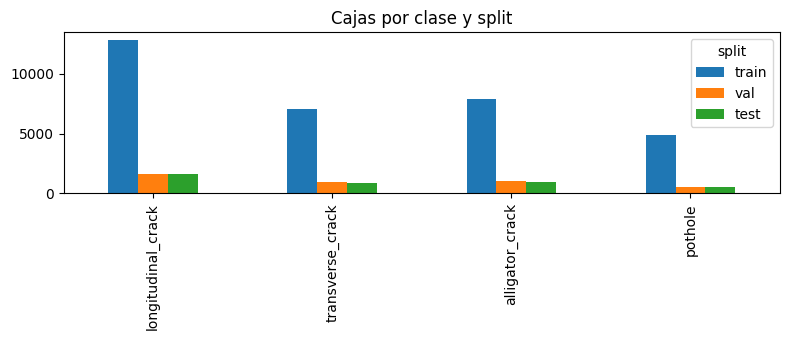

OK: sin nombres repetidos y sin contenido idéntico entre splits.
Desbalance máx/mín en train: 2.6:1 (moderado).


In [ ]:
import matplotlib
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

rows = []
for s in ("train", "val", "test"):
    cnt = Counter()
    for t in (DS / "labels" / s).glob("*.txt"):
        for line in t.read_text().splitlines():
            cnt[int(line.split()[0])] += 1
    rows.append({"split": s, **{CLASS_NAMES[i]: cnt.get(i, 0) for i in range(4)}})
class_df = pd.DataFrame(rows).set_index("split")
display(class_df)
display(manifest_df.pivot_table(index="country", columns="split", values="name", aggfunc="count", fill_value=0))

class_df.T.plot(kind="bar", figsize=(8, 3.5), title="Cajas por clase y split")
plt.tight_layout()
plt.show()

# --- comprobaciones anti-fuga
assert manifest_df["name"].is_unique, "Nombres repetidos entre splits"
dup_hash = manifest_df.groupby("md5")["split"].nunique()
assert (dup_hash <= 1).all(), "Hay contenido idéntico en más de un split"
print("OK: sin nombres repetidos y sin contenido idéntico entre splits.")

tr = class_df.loc["train"]
nonzero = tr[tr > 0]
if len(nonzero) < 4:
    print("AVISO: alguna clase no tiene ejemplos en train:", list(tr[tr == 0].index))
elif nonzero.max() / nonzero.min() > 10:
    print(f"AVISO: desbalance {nonzero.max() / nonzero.min():.0f}:1 entre clases. "
          "Entrena primero con CLS_PW=0.0 y, si la clase rara rinde mal, prueba CLS_PW=0.25.")
else:
    print(f"Desbalance máx/mín en train: {nonzero.max() / nonzero.min():.1f}:1 (moderado).")

## 10) Archivo YAML del dataset
Ultralytics lo usa para encontrar imágenes, etiquetas y nombres de clase. **Verificación:** se vuelve a leer y se imprime.

In [ ]:
import yaml
DATA_YAML = DS / "data.yaml"
cfg_yaml = {
    "path": str(DS),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: n for i, n in enumerate(CLASS_NAMES)},
}
DATA_YAML.write_text(yaml.safe_dump(cfg_yaml, sort_keys=False))
print(DATA_YAML.read_text())
assert yaml.safe_load(DATA_YAML.read_text())["names"][3] == "pothole"

path: /content/rdd2022_yolo
train: images/train
val: images/val
test: images/test
names:
  0: longitudinal_crack
  1: transverse_crack
  2: alligator_crack
  3: pothole



## 11) Comprobación visual de las etiquetas
Dibuja las cajas convertidas sobre imágenes de train. **Verificación importante:** las cajas deben cubrir el daño. Si salen desplazadas o escaladas, hay un error de conversión y **no debes entrenar**.

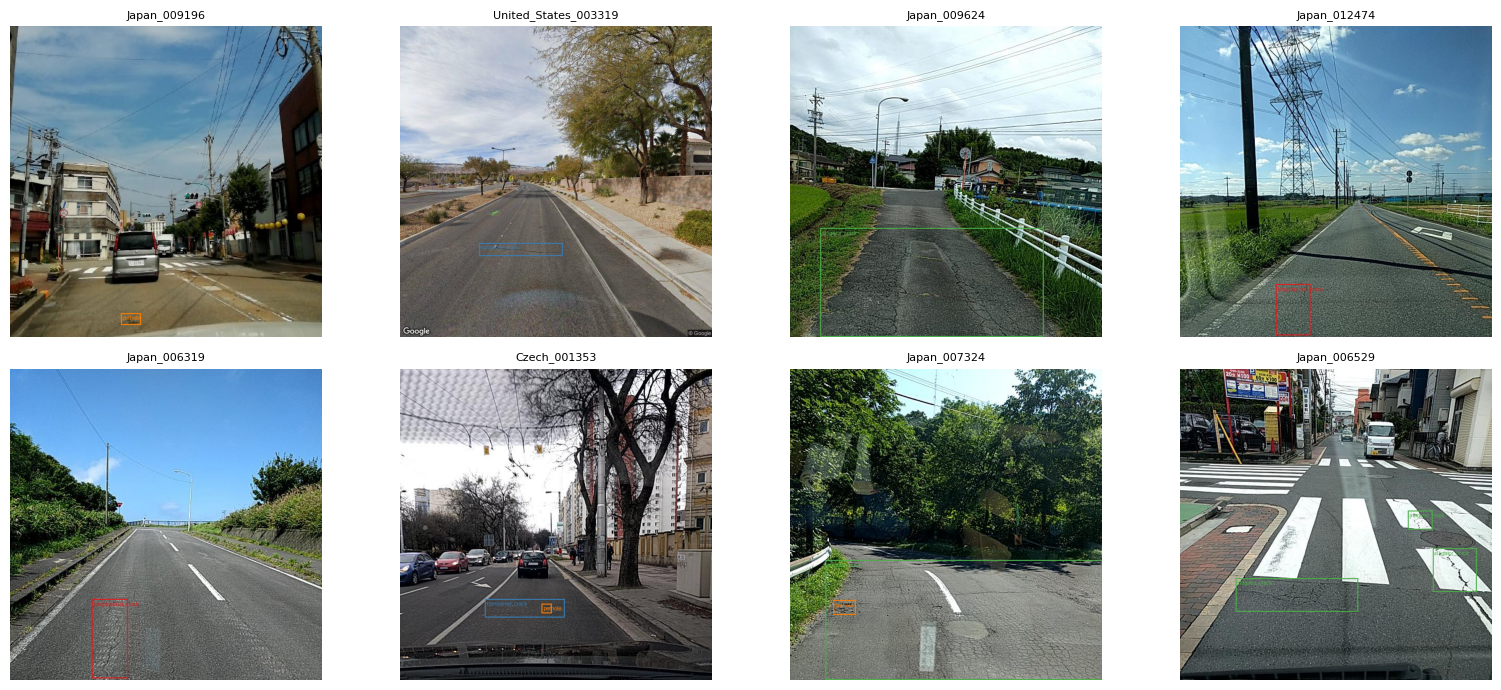

In [ ]:
from PIL import ImageDraw
COLORS = ["#e41a1c", "#377eb8", "#4daf4a", "#ff7f00"]

def draw_gt(img_path, label_path):
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    d = ImageDraw.Draw(im)
    lw = max(2, W // 300)
    if Path(label_path).exists():
        for line in Path(label_path).read_text().splitlines():
            cid, cx, cy, w, h = line.split()
            cid = int(cid); cx, cy, w, h = (float(v) for v in (cx, cy, w, h))
            box = [(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H]
            d.rectangle(box, outline=COLORS[cid], width=lw)
            d.text((box[0] + 3, box[1] + 3), CLASS_NAMES[cid], fill=COLORS[cid])
    return im

with_boxes = manifest_df[(manifest_df.split == "train") & (manifest_df.n_boxes > 0)]
sample = with_boxes.sample(min(8, len(with_boxes)), random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ip = next((DS / "images" / "train").glob(r["name"] + ".*"))
    ax.imshow(draw_gt(ip, DS / "labels" / "train" / (r["name"] + ".txt")))
    ax.set_title(r["name"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 12) Entrenar YOLO26s
- `smoke`: 2 épocas sobre un mini-subconjunto; solo comprueba el flujo.
- `benchmark`: 1 época con una muestra aleatoria del 5 % de las imágenes de entrenamiento (la validación no se reduce). Mide por separado cuánto tarda una validación completa y estima el tiempo de una época completa; es una **estimación aproximada**, no una medición.
- `full`: usa un **presupuesto de tiempo** (`time=TIME_HOURS`) en lugar de un número fijo de épocas; la documentación indica que `time` anula `epochs`. Se guarda en tu Drive tras cada época, y la **celda 13** reanuda si Colab se desconecta.

`batch=-1` deja que Ultralytics elija el lote según la memoria de tu GPU (si hay un error de memoria, reintenta con la mitad). **Verificación:** al terminar se imprime la carpeta de la corrida y la ruta de `best.pt`.

In [ ]:
from ultralytics import YOLO
import time as _time

run_name = f"{MODE}_{Path(PROFILE['model']).stem}"
train_args = dict(
    data=str(DATA_YAML), imgsz=PROFILE["imgsz"], batch=PROFILE["batch"], device=DEVICE,
    workers=min(8, os.cpu_count() or 2), seed=SEED, cls_pw=CLS_PW, plots=True,
    project=str(RUNS_DIR), name=run_name, patience=PROFILE.get("patience", 100),
)
if MODE == "smoke":
    train_args.update(epochs=2)
elif MODE == "benchmark":
    # 'fraction' tomaría las primeras N imágenes por orden alfabético (= un solo país).
    # Usamos en cambio una muestra aleatoria del 5 % de train, de todos los países.
    imgs = sorted((DS / "images" / "train").iterdir())
    sub = random.Random(SEED).sample(imgs, min(len(imgs), max(32, round(0.05 * len(imgs)))))
    (DS / "train_bench.txt").write_text("\n".join(str(p_) for p_ in sub))
    BENCH_YAML = DS / "data_bench.yaml"
    BENCH_YAML.write_text(yaml.safe_dump({**cfg_yaml, "train": "train_bench.txt"}, sort_keys=False))
    BENCH_FRAC = len(sub) / len(imgs)
    print(f"Benchmark: {len(sub)} de {len(imgs)} imágenes de train ({BENCH_FRAC:.1%}); por país:",
          dict(Counter(p_.name.rsplit('_', 1)[0] for p_ in sub)))
    train_args.update(data=str(BENCH_YAML), epochs=1)
else:
    # Con presupuesto de tiempo, Ultralytics recalcula el nº de épocas tras la primera; con pocas épocas
    # el valor por defecto close_mosaic=10 desactivaría el mosaic en casi todo el entrenamiento.
    train_args.update(epochs=100, time=TIME_HOURS, close_mosaic=3)
assert MODE != "full" or "time" in train_args, \
    "MODE='full' debe usar time=TIME_HOURS: revisa que el primer if diga MODE == \"smoke\" y que el else conserve la línea con time="
print("Argumentos de entrenamiento:", train_args)

model = YOLO(PROFILE["model"])
t0 = _time.time()
results = model.train(**train_args)
elapsed = _time.time() - t0

SAVE_DIR = Path(model.trainer.save_dir)
BEST = SAVE_DIR / "weights" / "best.pt"
(OUT_DIR / f"last_run_{MODE}.txt").write_text(str(SAVE_DIR))
print(f"\nTiempo total: {elapsed / 60:.1f} min | carpeta: {SAVE_DIR}\nbest.pt: {BEST} (existe: {BEST.exists()})")
if MODE == "benchmark":
    t1 = _time.time()
    model.val(data=str(DATA_YAML), split="val", imgsz=PROFILE["imgsz"], device=DEVICE, plots=False, verbose=False)
    t_val = _time.time() - t1
    est_epoch = max(elapsed - t_val, 1.0) / BENCH_FRAC + t_val
    print(f"Validación completa: {t_val:.0f} s | corrida de 5 % de train + val: {elapsed:.0f} s")
    print(f"ESTIMACIÓN (cota superior: escala también el arranque y AutoBatch): ~{est_epoch / 60:.1f} min por época con el dataset completo. "
          f"Con TIME_HOURS={TIME_HOURS} caben unas {TIME_HOURS * 3600 / est_epoch:.0f} épocas.")

Argumentos de entrenamiento: {'data': '/content/rdd2022_yolo/data.yaml', 'imgsz': 640, 'batch': -1, 'device': 0, 'workers': 2, 'seed': 0, 'cls_pw': 0.0, 'plots': True, 'project': '/content/drive/MyDrive/rdd2022_yolo26/runs', 'name': 'full_yolo26s', 'patience': 20, 'epochs': 100, 'time': 4.0, 'close_mosaic': 3}
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rdd2022_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torch

### 13) (Solo si Colab se desconectó) Reanudar el entrenamiento
Ejecuta antes las celdas 1–4 y 10 (necesitas `OUT_DIR`, `DATA_YAML` y `MODE`), y luego esta celda. Carga el último punto guardado y continúa donde se quedó. Si no se interrumpió nada, **no la ejecutes**.

In [ ]:
RESUME = False   # cámbialo a True solo si necesitas reanudar
if RESUME:
    from ultralytics import YOLO
    SAVE_DIR = Path((OUT_DIR / f"last_run_{MODE}.txt").read_text().strip())
    model = YOLO(SAVE_DIR / "weights" / "last.pt")
    model.train(resume=True)
    SAVE_DIR = Path(model.trainer.save_dir)
    BEST = SAVE_DIR / "weights" / "best.pt"
    print("Reanudado. best.pt:", BEST)

## 14) Curvas de entrenamiento y detección de sobreajuste
Compara pérdida de entrenamiento y de validación. **Señal de sobreajuste (heurística, no regla exacta):** la pérdida de validación sube durante varias épocas mientras la de entrenamiento sigue bajando, y el mAP de validación deja de mejorar o cae. Con pocas épocas (p. ej. en `smoke`) no hay curvas que interpretar.

Columnas disponibles: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6', 'lr/pg7']


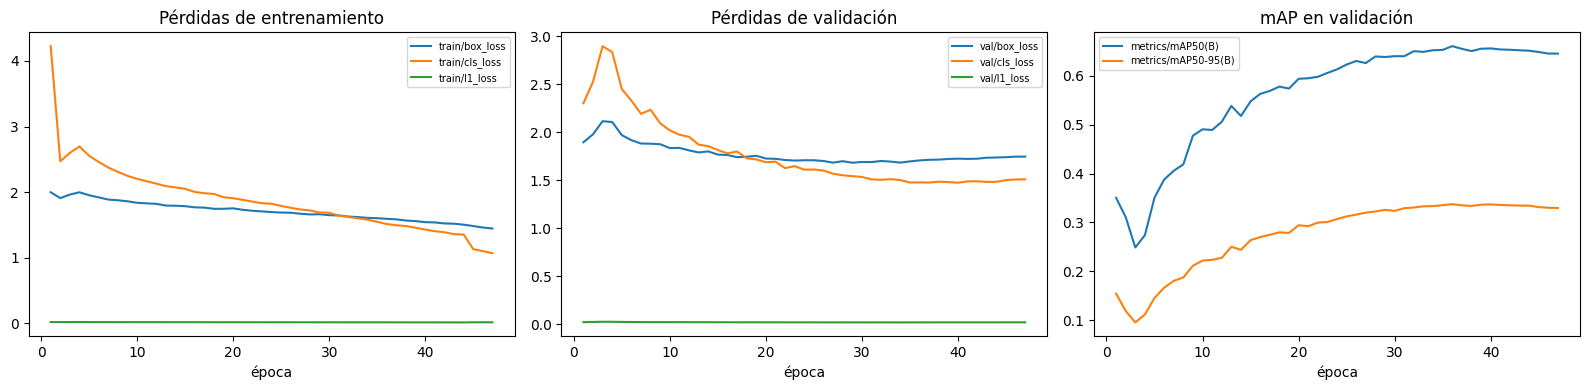

Pérdida de validación mínima en la época 35 de 47.
No se observa una señal clara de sobreajuste con esta heurística.


In [ ]:
res = pd.read_csv(SAVE_DIR / "results.csv")
res.columns = res.columns.str.strip()
print("Columnas disponibles:", list(res.columns))

tr_cols = [c for c in res.columns if c.startswith("train/") and c.endswith("loss")]
va_cols = [c for c in res.columns if c.startswith("val/") and c.endswith("loss")]
map_cols = [c for c in res.columns if c.startswith("metrics/mAP")]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c in tr_cols:
    ax[0].plot(res["epoch"], res[c], label=c)
ax[0].set_title("Pérdidas de entrenamiento"); ax[0].legend(fontsize=7)
for c in va_cols:
    ax[1].plot(res["epoch"], res[c], label=c)
ax[1].set_title("Pérdidas de validación"); ax[1].legend(fontsize=7)
for c in map_cols:
    ax[2].plot(res["epoch"], res[c], label=c)
ax[2].set_title("mAP en validación"); ax[2].legend(fontsize=7)
for a in ax:
    a.set_xlabel("época")
plt.tight_layout()
plt.show()

if len(res) >= 10 and va_cols and tr_cols:
    vl = res[va_cols].sum(axis=1).reset_index(drop=True)
    tl = res[tr_cols].sum(axis=1).reset_index(drop=True)
    e_min = int(vl.idxmin())
    tail = len(res) - 1 - e_min
    print(f"Pérdida de validación mínima en la época {int(res['epoch'].iloc[e_min])} de {len(res)}.")
    if tail >= 5 and vl.iloc[-1] > vl.iloc[e_min] * 1.05 and tl.iloc[-1] < tl.iloc[e_min]:
        print("POSIBLE SOBREAJUSTE: la validación empeora mientras el entrenamiento mejora.")
    else:
        print("No se observa una señal clara de sobreajuste con esta heurística.")
else:
    print("Pocas épocas: no se evalúa sobreajuste.")

## 15) Evaluar en validación y en prueba (test)
Métricas globales y **por clase**. El conjunto de **test se usa una sola vez**, al final: no ajustes hiperparámetros mirándolo. **Verificación:** las tablas se guardan también en tu Drive como CSV/JSON. Los números que salgan aquí son los **medidos** que usaremos en la documentación.

In [ ]:
model = YOLO(str(BEST))

def eval_split(split):
    m = model.val(data=str(DATA_YAML), split=split, imgsz=PROFILE["imgsz"], device=DEVICE, plots=False, verbose=False)
    b = m.box
    overall = dict(split=split, precision=float(b.mp), recall=float(b.mr), mAP50=float(b.map50), mAP50_95=float(b.map))
    per_class = pd.DataFrame({
        "class": [m.names[int(i)] for i in b.ap_class_index],
        "precision": b.p, "recall": b.r, "AP50": b.ap50, "AP50-95": b.ap,
    })
    per_class.insert(0, "split", split)
    return overall, per_class

summary, per_cls = [], []
for sp in ("val", "test"):
    o, p = eval_split(sp)
    summary.append(o)
    per_cls.append(p)
summary_df = pd.DataFrame(summary)
per_class_df = pd.concat(per_cls)
print("RESUMEN")
display(summary_df.round(4))
print("POR CLASE")
display(per_class_df.round(4))
summary_df.to_csv(OUT_DIR / f"metrics_summary_{MODE}.csv", index=False)
per_class_df.to_csv(OUT_DIR / f"metrics_per_class_{MODE}.csv", index=False)

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2274.5±581.7 MB/s, size: 81.4 KB)
val: Scanning /content/rdd2022_yolo/labels/val.cache... 2100 images, 194 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2100/2100 629.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 132/132 3.8it/s 34.8s
                   all       2100       4126      0.672      0.602       0.66      0.337
Speed: 0.9ms preprocess, 13.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 509.0±528.6 MB/s, size: 77.8 KB)
val: Scanning /content/rdd2022_yolo/labels/test... 210

,split,precision,recall,mAP50,mAP50_95
0,val,0.6724,0.6019,0.6601,0.3375
1,test,0.6920,0.5969,0.6648,0.3526


POR CLASE


,split,class,precision,recall,AP50,AP50-95
0,val,longitudinal_crack,0.6549,0.6639,0.6945,0.3923
1,val,transverse_crack,0.6348,0.5790,0.6146,0.3073
2,val,alligator_crack,0.7213,0.6602,0.7467,0.3977
3,val,pothole,0.6783,0.5043,0.5845,0.2526
0,test,longitudinal_crack,0.6840,0.6498,0.7032,0.4073
1,test,transverse_crack,0.6561,0.5746,0.6475,0.3326
2,test,alligator_crack,0.7361,0.6579,0.7364,0.4079
3,test,pothole,0.6920,0.5055,0.5719,0.2625


## 16) Visualizar predicciones
Izquierda: etiquetas reales (verdad terreno). Derecha: lo que predice el modelo (`conf=0.25`). Se usan imágenes del split de **test**. **Verificación:** las detecciones deben coincidir razonablemente con las cajas reales (en `smoke` no lo harán).

Si rellenaste `ECU_DIR` en la celda 3, también se muestran predicciones sobre **tus fotos de Ecuador** (sin etiquetas, así que sin métricas: sirven para una inspección visual de la brecha de dominio).

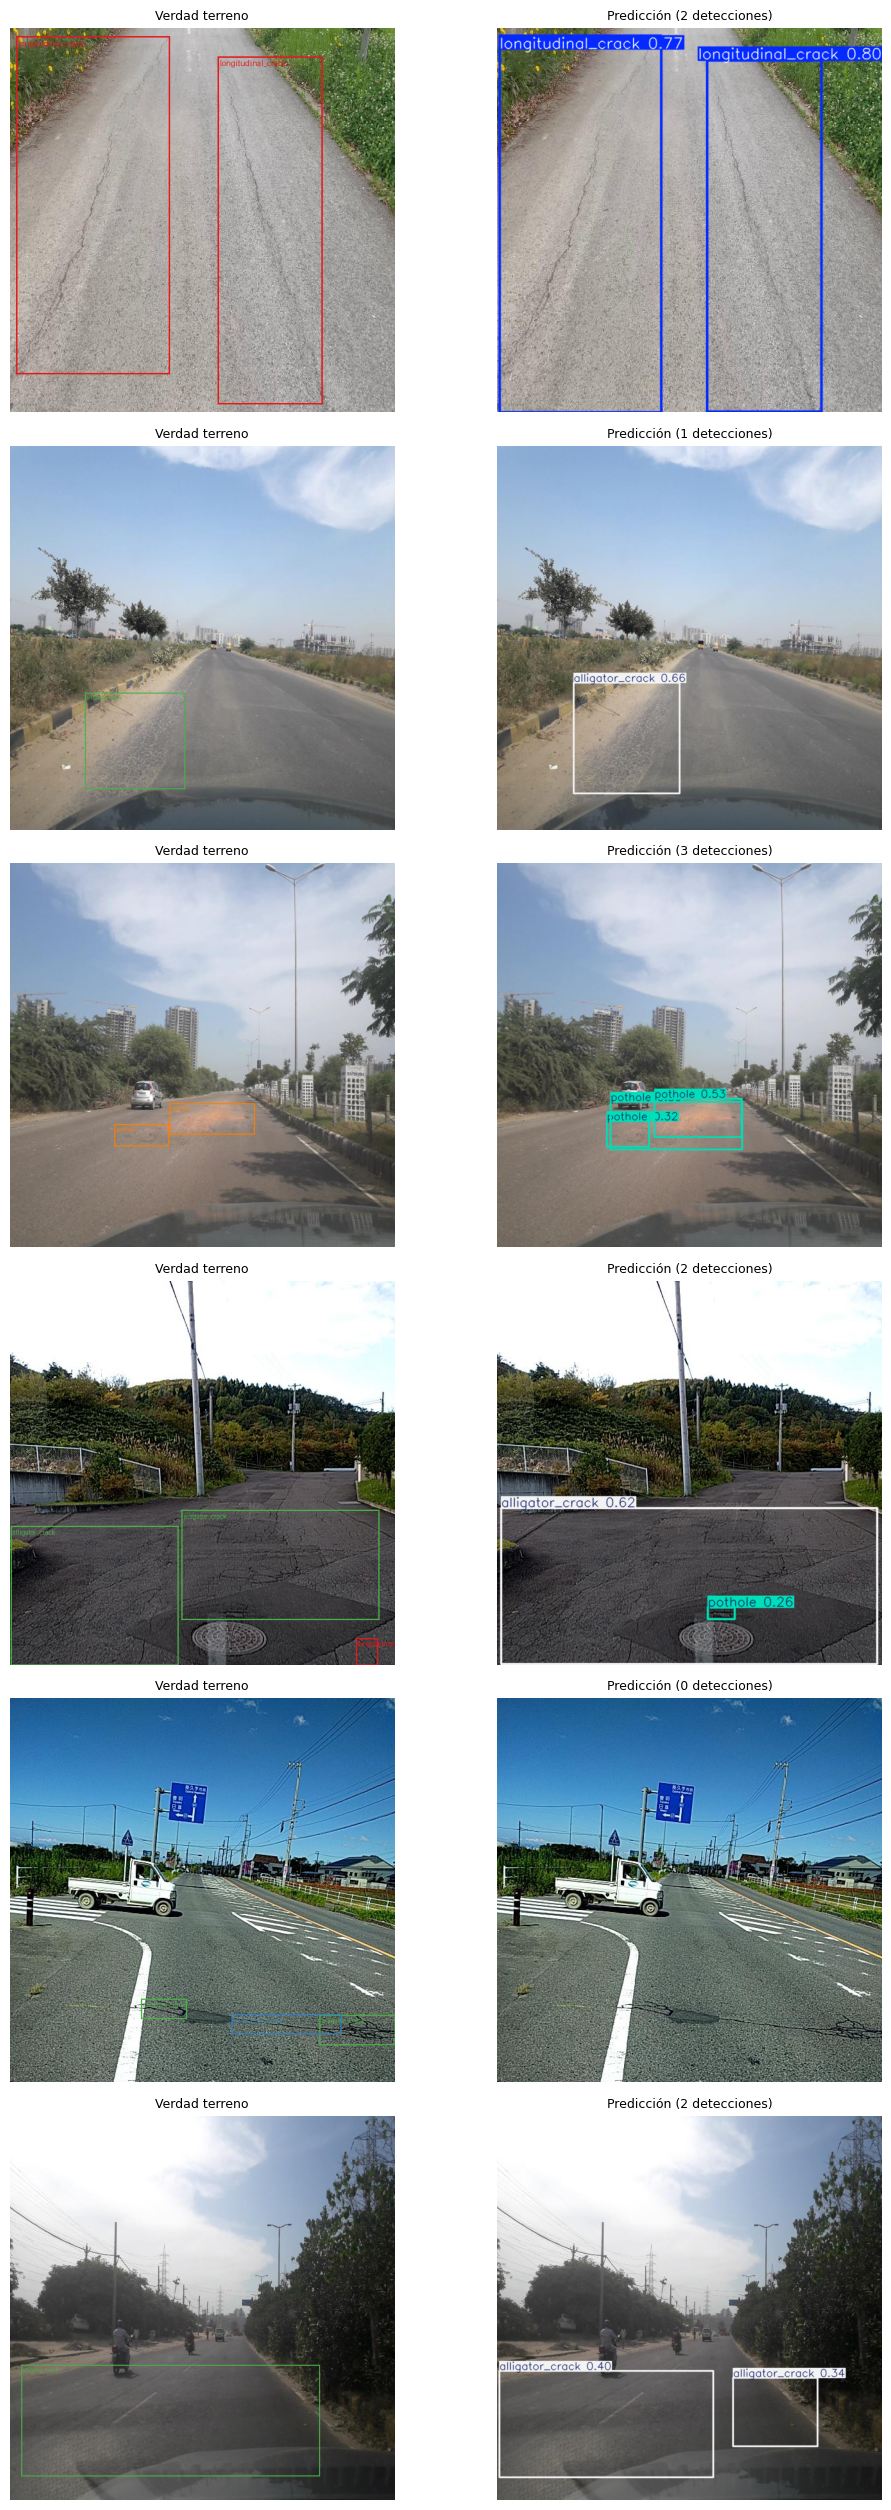

In [ ]:
test_df = manifest_df[manifest_df.split == "test"]
pick = test_df[test_df.n_boxes > 0].sample(min(6, int((test_df.n_boxes > 0).sum())), random_state=SEED)
fig, axes = plt.subplots(len(pick), 2, figsize=(11, 4.2 * len(pick)))
axes = axes.reshape(len(pick), 2)
for row, (_, r) in zip(axes, pick.iterrows()):
    ip = next((DS / "images" / "test").glob(r["name"] + ".*"))
    row[0].imshow(draw_gt(ip, DS / "labels" / "test" / (r["name"] + ".txt")))
    row[0].set_title("Verdad terreno", fontsize=9)
    pred = model.predict(str(ip), imgsz=PROFILE["imgsz"], conf=0.25, device=DEVICE, verbose=False)[0]
    row[1].imshow(pred.plot()[..., ::-1])
    row[1].set_title(f"Predicción ({len(pred.boxes)} detecciones)", fontsize=9)
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.show()

if ECU_DIR and Path(ECU_DIR).is_dir():
    eimgs = sorted(p for p in Path(ECU_DIR).iterdir() if p.suffix.lower() in IMG_EXT)[:8]
    print(f"Predicciones sobre {len(eimgs)} fotos de {ECU_DIR}")
    if eimgs:
        fig, axes = plt.subplots(2, 4, figsize=(16, 7))
        for ax, p in zip(axes.ravel(), eimgs):
            pr = model.predict(str(p), imgsz=PROFILE["imgsz"], conf=0.25, device=DEVICE, verbose=False)[0]
            ax.imshow(pr.plot()[..., ::-1]); ax.set_title(f"{p.name} ({len(pr.boxes)})", fontsize=8); ax.axis("off")
        plt.tight_layout()
        plt.show()

## 17) Guardar y descargar el mejor modelo
Copia `best.pt`, `last.pt`, el historial, la configuración y las versiones a `OUT_DIR/final_<modo>` (en tu Drive) y, en Colab, descarga `best.pt` a tu computadora. El archivo `run_info.json` conserva todo lo necesario para reproducir y documentar la corrida. **Verificación:** se imprime el SHA-256 de `best.pt`.

In [ ]:
import datetime
elapsed = globals().get("elapsed", float("nan"))
train_args = globals().get("train_args", {})
FINAL = OUT_DIR / f"final_{MODE}"
FINAL.mkdir(parents=True, exist_ok=True)
for name in ("weights/best.pt", "weights/last.pt", "results.csv", "args.yaml"):
    src = SAVE_DIR / name
    if src.exists():
        shutil.copy2(src, FINAL / Path(name).name)
shutil.copy2(DATA_YAML, FINAL / "data.yaml")

sha = hashlib.sha256((FINAL / "best.pt").read_bytes()).hexdigest()
info = dict(
    fecha=datetime.datetime.now().isoformat(timespec="seconds"),
    modo=MODE, modelo=PROFILE["model"], imgsz=PROFILE["imgsz"], paises=COUNTRIES, seed=SEED,
    bloque_split=BLOCK, val_frac=VAL_FRAC, test_frac=TEST_FRAC, cls_pw=CLS_PW,
    ultralytics=ultralytics.__version__, torch=torch.__version__, cuda=torch.cuda.is_available(),
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    imagenes_por_split=manifest_df.groupby("split").size().to_dict(),
    cajas_por_clase=class_df.to_dict(orient="index"),
    metricas_resumen=summary_df.round(4).to_dict(orient="records"),
    tiempo_entrenamiento_min=round(elapsed / 60, 2),
    sha256_best_pt=sha,
    argumentos_entrenamiento={k: v for k, v in train_args.items() if k != "project"},
)
(FINAL / "run_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str))
print("Guardado en:", FINAL)
print("Archivos:", sorted(p.name for p in FINAL.iterdir()))
print("SHA-256 de best.pt:", sha)

if IN_COLAB:
    from google.colab import files
    files.download(str(FINAL / "best.pt"))

Guardado en: /content/drive/MyDrive/rdd2022_yolo26/final_full
Archivos: ['args.yaml', 'best.pt', 'data.yaml', 'last.pt', 'results.csv', 'run_info.json']
SHA-256 de best.pt: 59e030a042fa97d8e1da8de5dd989e94e1c47227de795a89f827def471ba8d88


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
**Siguiente paso (Fase 5):** con `best.pt` y `run_info.json` en mano diseñamos la aplicación web (FastAPI + frontend) y el módulo de **seguimiento** con PostgreSQL.